Best Route: [3, 2, 0, 1, 4, 3]
Shortest Distance: 22.34


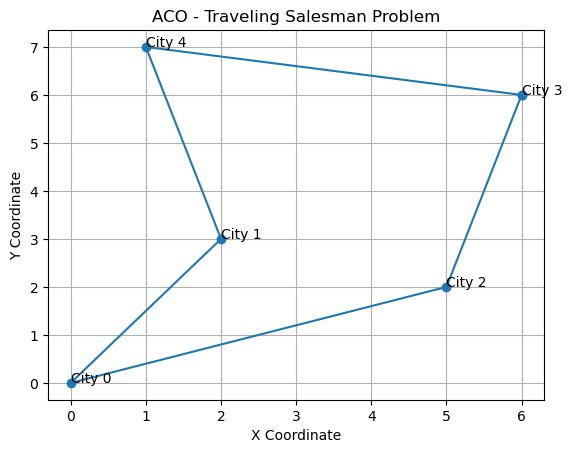

In [2]:

import random
import math
import matplotlib.pyplot as plt

# Define cities
cities = [(0, 0), (2, 3), (5, 2), (6, 6), (1, 7)]
n = len(cities)

# Parameters
num_ants = 10
iterations = 50
alpha = 1
beta = 2
rho = 0.5
Q = 100

# Calculate distance
def distance(i, j):
    x1, y1 = cities[i]
    x2, y2 = cities[j]
    return math.sqrt((x2-x1)**2 + (y2-y1)**2)

# Distance matrix
dist = [[distance(i, j) for j in range(n)] for i in range(n)]

# Initialize pheromone
pheromone = [[1.0 for j in range(n)] for i in range(n)]

# Calculate route length
def route_distance(route):
    total = 0
    for i in range(n):
        total += dist[route[i]][route[(i+1) % n]]
    return total

# Select next city
def select_city(current, unvisited):
    probabilities = []
    for city in unvisited:
        tau = pheromone[current][city] ** alpha
        eta = (1 / dist[current][city]) ** beta
        probabilities.append(tau * eta)

    return random.choices(
        unvisited,
        weights=probabilities,
        k=1
    )[0]

# ACO algorithm
best_route = None
best_distance = float('inf')

for _ in range(iterations):

    all_routes = []

    for ant in range(num_ants):
        start = random.randint(0, n-1)
        route = [start]
        unvisited = list(range(n))
        unvisited.remove(start)

        while unvisited:
            current = route[-1]
            next_city = select_city(current, unvisited)
            route.append(next_city)
            unvisited.remove(next_city)

        d = route_distance(route)
        all_routes.append((route, d))

        if d < best_distance:
            best_distance = d
            best_route = route.copy()

    # Evaporation
    for i in range(n):
        for j in range(n):
            pheromone[i][j] *= (1-rho)

    # Pheromone update
    for route, d in all_routes:
        deposit = Q / d

        for i in range(n):
            a = route[i]
            b = route[(i+1) % n]
            pheromone[a][b] += deposit
            pheromone[b][a] += deposit

# Display result
print("Best Route:", best_route + [best_route[0]])
print("Shortest Distance:", round(best_distance, 2))

# Plot best route
x = [cities[i][0] for i in best_route]
y = [cities[i][1] for i in best_route]

x.append(x[0])
y.append(y[0])

plt.plot(x, y, marker='o')
for i, (cx, cy) in enumerate(cities):
    plt.text(cx, cy, f"City {i}")

plt.title("ACO - Traveling Salesman Problem")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid()
plt.show()
